In [10]:
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
df = pd.read_csv('benchmark_data/benchmark_encoding.csv')
df.head()

,size,clue_ratio,sample,encoding_method,variables,clauses,encoding_time,solve_time,total_time,status,error
0,9,clue_70,sudoku_01,Pairwise,729,12045,25,0,25,SUCCESS,NaN
1,9,clue_70,sudoku_01,Bitwise,2025,12045,20,0,20,SUCCESS,NaN
2,9,clue_70,sudoku_01,SeqCounter,3321,7833,18,0,18,SUCCESS,NaN
3,9,clue_70,sudoku_02,Pairwise,729,12045,18,0,18,SUCCESS,NaN
4,9,clue_70,sudoku_02,Bitwise,2025,12045,31,0,31,SUCCESS,NaN


In [14]:
df_mean = df.groupby(['encoding_method', 'size'], as_index = False)[['variables', 'clauses', 'encoding_time', 'solve_time', 'total_time']].mean()
df_mean.head()

,encoding_method,size,variables,clauses,encoding_time,solve_time,total_time
0,Bitwise,9,2025.0,12045.0,20.6,0.0,20.6
1,Bitwise,16,8192.0,66739.0,83.2,1.0,84.2
2,Bitwise,25,28125.0,315438.0,401.4,3.0,404.4
3,Bitwise,36,77760.0,1125835.0,1750.6,9.6,1760.2
4,Bitwise,49,175273.0,2834861.0,4633.0,26.0,4659.0


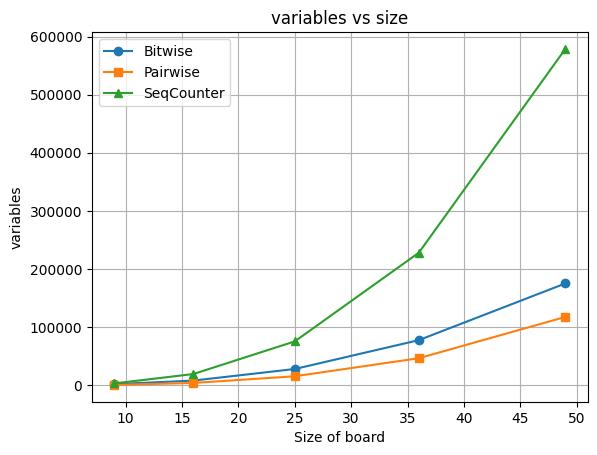

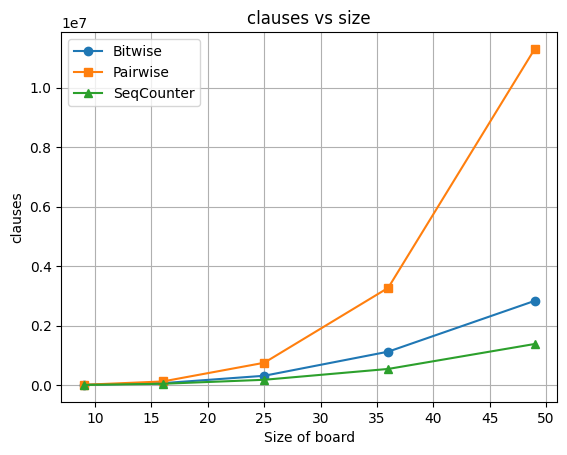

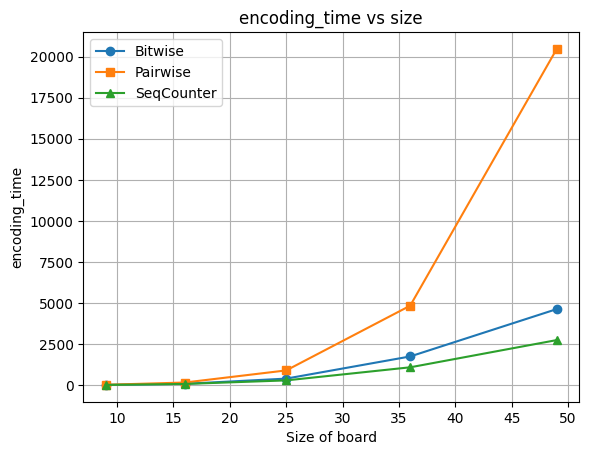

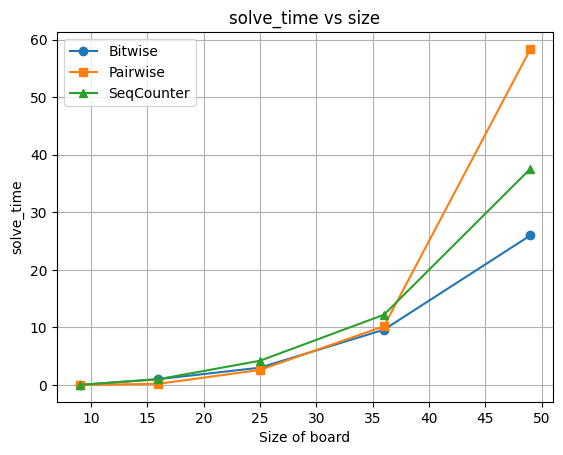

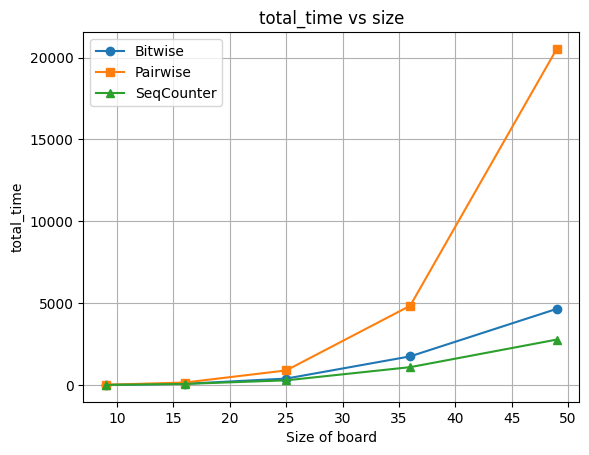

In [15]:
features = ['variables', 'clauses', 'encoding_time', 'solve_time', 'total_time']

encodings = df_mean['encoding_method'].unique()
available_markers = ['o', 's', '^', 'D', 'x', '*', 'v']

encoding_marker_map = {encoding: available_markers[i % len(available_markers)] for i, encoding in enumerate(encodings)}

for feature in features:
    for encoding, data in df_mean.groupby('encoding_method'):
        plt.plot(data['size'], data[feature], label = encoding, marker=encoding_marker_map[encoding])

    plt.xlabel('Size of board')
    plt.ylabel(feature)
    plt.title(f"{feature} vs size")
    plt.legend()
    plt.grid(True)
    plt.show()

In [30]:
df = pd.read_csv("benchmark_data/benchmark_encoding.csv")

# 2. Pivot bảng
pivot_df = df.pivot_table(
    index="size",
    columns="encoding_method",
    values=["variables", "clauses"],
    aggfunc="max"
)

# Swap level để tên phương pháp ra ngoài
pivot_df = pivot_df.swaplevel(axis=1).sort_index(axis=1)

# Sắp xếp thứ tự phương pháp
enc_order = ["Pairwise", "Bitwise", "SeqCounter"]
pivot_df = pivot_df.reindex(columns=enc_order, level=0)

# SẮP XẾP LẠI CỘT CON: Ép 'variables' đứng trước, 'clauses' đứng sau cho chuẩn mẫu báo cáo
pivot_df = pivot_df.reindex(columns=["variables", "clauses"], level=1)

# Xử lý số liệu và định dạng dấu phẩy hàng nghìn
pivot_df = pivot_df.fillna(0).astype(int)
formatted_df = pivot_df.map(lambda x: f"{x:,}")

# 3. Gõ chữ formatted_df ở đây để Jupyter Notebook in ra bảng có dấu phẩy
formatted_df

encoding_method  Pairwise               Bitwise            SeqCounter  \
                variables     clauses variables    clauses  variables   
size                                                                    
9                     729      12,045     2,025     12,045      3,321   
16                  4,096     124,083     8,192     66,739     19,456   
25                 15,625     752,938    28,125    315,438     75,625   
36                 46,656   3,272,011    77,760  1,125,835    228,096   
49                117,649  11,305,589   175,273  2,834,861    578,641   

encoding_method             
                   clauses  
size                        
9                    7,833  
16                  46,259  
25                 180,438  
36                 545,227  
49               1,384,657

In [31]:
# 1. Chỉ gọi to_latex cơ bản để lấy phần nội dung bảng (tabular)
latex_code = formatted_df.to_latex()

# 2. In ra hoặc bọc thủ công vào môi trường table của LaTeX
print(latex_code)

\begin{tabular}{lllllll}
\toprule
encoding_method & \multicolumn{2}{r}{Pairwise} & \multicolumn{2}{r}{Bitwise} & \multicolumn{2}{r}{SeqCounter} \\
 & variables & clauses & variables & clauses & variables & clauses \\
size &  &  &  &  &  &  \\
\midrule
9 & 729 & 12,045 & 2,025 & 12,045 & 3,321 & 7,833 \\
16 & 4,096 & 124,083 & 8,192 & 66,739 & 19,456 & 46,259 \\
25 & 15,625 & 752,938 & 28,125 & 315,438 & 75,625 & 180,438 \\
36 & 46,656 & 3,272,011 & 77,760 & 1,125,835 & 228,096 & 545,227 \\
49 & 117,649 & 11,305,589 & 175,273 & 2,834,861 & 578,641 & 1,384,657 \\
\bottomrule
\end{tabular}



In [34]:
en_df = df.groupby(['encoding_method', 'size'])[['encoding_time']].mean()
en_df

encoding_time
encoding_method size               
Bitwise         9              20.6
                16             83.2
                25            401.4
                36           1750.6
                49           4633.0
Pairwise        9              26.2
                16            163.0
                25            900.6
                36           4841.2
                49          20468.8
SeqCounter      9              17.6
                16             77.0
                25            293.2
                36           1090.2
                49           2747.2